In [156]:
#come back and remove any functions we are not neededing or include ones that we need
# Add classification models

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# DATA CLEANING AND FEATURE ENGINEERING
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# CLUSTERING AND DIMENSIONALITY REDUCTION
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


# DATA SPLITTING AND EVALUATION
from sklearn.model_selection import train_test_split, cross_validate, KFold


# REGRESSION MODELS
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
print("Libraries loaded successfully.")

DATA_PATH = Path("MedHealth_SYNTHEA_GroupCW_Dataset_Final.csv")

##### we will need to insert what we are putting as the target column etc here (from lab 3)


if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put the CSV file in the same folder as this notebook."
    )

raw = pd.read_csv(DATA_PATH)
print(f"Loaded {raw.shape[0]:,} rows and {raw.shape[1]:,} columns.")
display(raw.head())


Libraries loaded successfully.
Loaded 297 rows and 52 columns.


,PATIENT_ID,BIRTH_DATE,SEX,RACE,YEAR,PERIOD_START,PERIOD_END,RECORD_CUTOFF_DATE,ENCOUNTER_SYMPTOM_RECORDS,ENCOUNTER_CHECK_UP_RECORDS,...,HYPERTENSION_HISTORY,ISCHEMIC_HEART_DISEASE_HISTORY,HYPERLIPIDEMIA_HISTORY,CHRONIC_PAIN_HISTORY,ASTHMA_HISTORY,CHRONIC_KIDNEY_DISEASE_HISTORY,STRESS_HISTORY,SOCIAL_ISOLATION_HISTORY,UNEMPLOYMENT_HISTORY,HOUSING_UNSATISFACTORY_HISTORY
0,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,20/01/1981,F,white,2023,01/01/2023,31/12/2023,25/08/2026,0,0,...,1,0,0,0,0,0,1,1,0,0
1,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,20/01/1981,F,white,2024,01/01/2024,31/12/2024,25/08/2026,0,0,...,1,0,0,0,0,0,1,1,0,0
2,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,20/01/1981,F,white,2025,01/01/2025,31/12/2025,25/08/2026,0,1,...,1,0,0,0,0,0,1,1,0,0
3,029c95e2-d252-d8d3-3626-7f347182d6d7,01/11/1972,F,white,2023,01/01/2023,31/12/2023,19/08/2026,0,0,...,0,0,0,1,0,0,1,1,0,0
4,029c95e2-d252-d8d3-3626-7f347182d6d7,01/11/1972,F,white,2024,01/01/2024,31/12/2024,19/08/2026,0,2,...,0,0,0,1,0,0,1,1,0,0


In [157]:
display(pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "missing_percent": (100 * raw.isna().mean()).round(1),
    "unique_values": raw.nunique(dropna=True)
}).sort_values("missing_n", ascending=False))

print("Exact duplicate rows:", raw.duplicated().sum())
display(raw.describe(include="all").T)

,dtype,missing_n,missing_percent,unique_values
GLUCOSE_LAST_RECORDED,float64,176,59.3,107
GLUCOSE_DATE,object,176,59.3,101
CREATININE_LAST_RECORDED,float64,176,59.3,83
CREATININE_DATE,object,176,59.3,101
TRIGLYCERIDES_LAST_RECORDED,float64,128,43.1,96
TRIGLYCERIDES_DATE,object,128,43.1,97
HDL_CHOLESTEROL_DATE,object,128,43.1,97
HDL_CHOLESTEROL_LAST_RECORDED,float64,128,43.1,99
TOTAL_CHOLESTEROL_DATE,object,128,43.1,97
TOTAL_CHOLESTEROL_LAST_RECORDED,float64,128,43.1,99


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PATIENT_ID,297,100,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BIRTH_DATE,297,96,06/11/1979,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEX,297,2,M,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RACE,297,3,white,242,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEAR,297.0,NaN,NaN,NaN,2024.0,0.817875,2023.0,2023.0,2024.0,2025.0,2025.0
PERIOD_START,297,6,01/01/2025,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PERIOD_END,297,4,31/12/2024,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RECORD_CUTOFF_DATE,297,10,23/08/2026,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENCOUNTER_SYMPTOM_RECORDS,297.0,NaN,NaN,NaN,0.296296,0.636518,0.0,0.0,0.0,0.0,5.0
ENCOUNTER_CHECK_UP_RECORDS,297.0,NaN,NaN,NaN,0.804714,1.795898,0.0,0.0,0.0,1.0,15.0


In [158]:
print(raw["PATIENT_ID"].value_counts().value_counts().loc[3])
print(raw["PATIENT_ID"].value_counts().value_counts().loc[2])
print(raw["PATIENT_ID"].value_counts().value_counts().loc[1])

raw["PATIENT_ID"].value_counts(dropna=False)

98
1
1


,count
PATIENT_ID,
00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,3
029c95e2-d252-d8d3-3626-7f347182d6d7,3
06476266-59b1-ded7-4138-3c7543fd4981,3
09c573e2-a45d-aa5e-6a17-3c682155e6e3,3
0f3d04a2-f42e-1429-acef-0becd0a0fcea,3
...,...
f6359fe4-4340-2820-8b76-593a45f5186c,3
fd0d7b3a-307d-07b8-9d7e-2424e1feb9e4,3
f67eaca3-2366-7ee2-6887-a5bd449b54a6,3


#Removing the kids:


In [159]:
# 1. Ensure dates are in datetime format to calculate AGE correctly
raw_dates = ["BIRTH_DATE", "PERIOD_START"]
for col in raw_dates:
    raw[col] = pd.to_datetime(raw[col], format="mixed", errors="coerce")

# 2. Calculate AGE directly on the raw DataFrame
raw["AGE"] = ((raw["PERIOD_START"] - raw["BIRTH_DATE"]).dt.days / 365.25).round(1)

# 3. Filter out patients who are 18 and under
no_kids_data = raw[raw["AGE"] > 18.0].copy()
print(f"Filtered out kids. Remaining adults: {no_kids_data.shape[0]}")


Filtered out kids. Remaining adults: 225


In [160]:
display(no_kids_data.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
PATIENT_ID,225,78,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BIRTH_DATE,225,NaN,NaN,NaN,1980-03-24 11:18:24,1930-06-11 00:00:00,1968-09-24 00:00:00,1981-07-29 00:00:00,1993-11-17 00:00:00,2006-10-30 00:00:00,NaN
SEX,225,2,M,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RACE,225,3,white,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEAR,225.0,NaN,NaN,NaN,2024.013333,2023.0,2023.0,2024.0,2025.0,2025.0,0.820932
PERIOD_START,225,NaN,NaN,NaN,2024-01-06 05:00:48,2023-01-01 00:00:00,2023-01-01 00:00:00,2024-01-01 00:00:00,2025-01-01 00:00:00,2025-01-01 00:00:00,NaN
PERIOD_END,225,4,31/12/2025,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RECORD_CUTOFF_DATE,225,10,23/08/2026,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENCOUNTER_SYMPTOM_RECORDS,225.0,NaN,NaN,NaN,0.24,0.0,0.0,0.0,0.0,5.0,0.594018
ENCOUNTER_CHECK_UP_RECORDS,225.0,NaN,NaN,NaN,0.902222,0.0,0.0,0.0,1.0,15.0,2.028644


In [161]:
id_cols = ["PATIENT_ID"]

categ_cols = [
    "SEX",
    "RACE",
]

history_cols = [

    "OBESITY_HISTORY",
    "PREDIABETES_HISTORY",
    "HYPERTENSION_HISTORY",
    "ISCHEMIC_HEART_DISEASE_HISTORY",
    "CHRONIC_PAIN_HISTORY",
    "ASTHMA_HISTORY",
    "CHRONIC_KIDNEY_DISEASE_HISTORY",
    "SOCIAL_ISOLATION_HISTORY",
    "UNEMPLOYMENT_HISTORY",
    "HOUSING_UNSATISFACTORY_HISTORY"
]

date_cols = [
    "BIRTH_DATE",
    "PERIOD_START",
    "PERIOD_END",
    "RECORD_CUTOFF_DATE",
    "HEIGHT_CM_DATE",
    "WEIGHT_KG_DATE",
    "PAIN_SCORE_DATE",
    "TOTAL_CHOLESTEROL_DATE",
    "HDL_CHOLESTEROL_DATE",
    "TRIGLYCERIDES_DATE",
    "GLUCOSE_DATE",
    "CREATININE_DATE"
]


no_kids_data[date_cols] = no_kids_data[date_cols].apply(
    pd.to_datetime,
    errors="coerce",
    dayfirst=True
)

#calculate BMI
no_kids_data["BMI"] = no_kids_data["WEIGHT_KG_LAST_IN_YEAR"] / ((no_kids_data["HEIGHT_CM_LAST_IN_YEAR"] / 100) ** 2)


measurement_cols = [
    "AGE",
    "BMI",
    "PAIN_SCORE_LAST_IN_YEAR",
    "TOTAL_CHOLESTEROL_LAST_RECORDED",
    "HDL_CHOLESTEROL_LAST_RECORDED",
    "TRIGLYCERIDES_LAST_RECORDED",
    "GLUCOSE_LAST_RECORDED",
    "CREATININE_LAST_RECORDED"
  ]

encounter_cols = [
    "ENCOUNTER_SYMPTOM_RECORDS", "ENCOUNTER_CHECK_UP_RECORDS", "ENCOUNTER_GENERAL_EXAM_RECORDS", "ENCOUNTER_PROBLEM_RECORDS",
    "ENCOUNTER_EMERGENCY_ROOM_RECORDS", "ENCOUNTER_URGENT_CARE_RECORDS", "ENCOUNTER_WELL_CHILD_RECORDS", "ENCOUNTER_PRENATAL_RECORDS",
    "ENCOUNTER_POSTNATAL_RECORDS", "ENCOUNTER_FOLLOW_UP_RECORDS", "ENCOUNTER_INPATIENT_RECORDS",
    "ENCOUNTER_OTHER_RECORDS"
]

new_encounter_cols = [
    "ENCOUNTER_EMERGENCY_ROOM_RECORDS",
    "ENCOUNTER_URGENT_CARE_RECORDS",
    "ENCOUNTER_INPATIENT_RECORDS",
]

#I deleted follow up encounter from  my new encounter cols


In [162]:
# Safely convert all other date columns to avoid turning valid dates into NaN
for col in date_cols:
    if col in no_kids_data.columns:
        no_kids_data[col] = pd.to_datetime(no_kids_data[col], format="mixed", errors="coerce")


In [163]:
# Clean boundary values for specific columns only instead of overwriting the whole row

no_kids_data.loc[(no_kids_data["PAIN_SCORE_LAST_IN_YEAR"] < 0) | (no_kids_data["PAIN_SCORE_LAST_IN_YEAR"] > 10), "PAIN_SCORE_LAST_IN_YEAR"] = np.nan
no_kids_data.loc[(no_kids_data["WEIGHT_KG_LAST_IN_YEAR"] < 0) | (no_kids_data["WEIGHT_KG_LAST_IN_YEAR"] > 200), "WEIGHT_KG_LAST_IN_YEAR"] = np.nan
no_kids_data.loc[(no_kids_data["HEIGHT_CM_LAST_IN_YEAR"] < 0) | (no_kids_data["HEIGHT_CM_LAST_IN_YEAR"] > 250), "HEIGHT_CM_LAST_IN_YEAR"] = np.nan
no_kids_data.loc[(no_kids_data["AGE"] < 0) | (no_kids_data["AGE"] > 115), "AGE"] = np.nan

Data cleaning

In [164]:
# Clean string and categorical columns specifically to avoid messing up numeric/date types

for col_name in categ_cols + id_cols:
    if col_name in no_kids_data.columns:
        no_kids_data[col_name] = no_kids_data[col_name].map(lambda x: str(x).strip() if pd.notna(x) else np.nan)
no_kids_data[categ_cols] = no_kids_data[categ_cols].replace(["nan", "", "na", "n/a", "{nan}"], np.nan)
no_kids_data[id_cols] = no_kids_data[id_cols].replace(["nan", "", "na", "n/a", "{nan}"], np.nan)
print("Categorical and ID columns stripped and cleaned successfully.")

# 3. Clean date columns correctly
no_kids_data[date_cols] = no_kids_data[date_cols].apply(pd.to_datetime, format="mixed", errors="coerce")

#needed gemini to help here

Categorical and ID columns stripped and cleaned successfully.


In [165]:
display(no_kids_data.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
PATIENT_ID,225,78,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BIRTH_DATE,225,NaN,NaN,NaN,1980-03-24 11:18:24,1930-06-11 00:00:00,1968-09-24 00:00:00,1981-07-29 00:00:00,1993-11-17 00:00:00,2006-10-30 00:00:00,NaN
SEX,225,2,M,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RACE,225,3,white,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEAR,225.0,NaN,NaN,NaN,2024.013333,2023.0,2023.0,2024.0,2025.0,2025.0,0.820932
PERIOD_START,225,NaN,NaN,NaN,2024-01-06 05:00:48,2023-01-01 00:00:00,2023-01-01 00:00:00,2024-01-01 00:00:00,2025-01-01 00:00:00,2025-01-01 00:00:00,NaN
PERIOD_END,225,NaN,NaN,NaN,2025-01-03 22:56:00,2023-08-22 00:00:00,2023-12-31 00:00:00,2024-12-31 00:00:00,2025-12-31 00:00:00,2025-12-31 00:00:00,NaN
RECORD_CUTOFF_DATE,225,NaN,NaN,NaN,2026-08-15 12:09:36,2023-08-22 00:00:00,2026-08-19 00:00:00,2026-08-22 00:00:00,2026-08-23 00:00:00,2026-08-25 00:00:00,NaN
ENCOUNTER_SYMPTOM_RECORDS,225.0,NaN,NaN,NaN,0.24,0.0,0.0,0.0,0.0,5.0,0.594018
ENCOUNTER_CHECK_UP_RECORDS,225.0,NaN,NaN,NaN,0.902222,0.0,0.0,0.0,1.0,15.0,2.028644


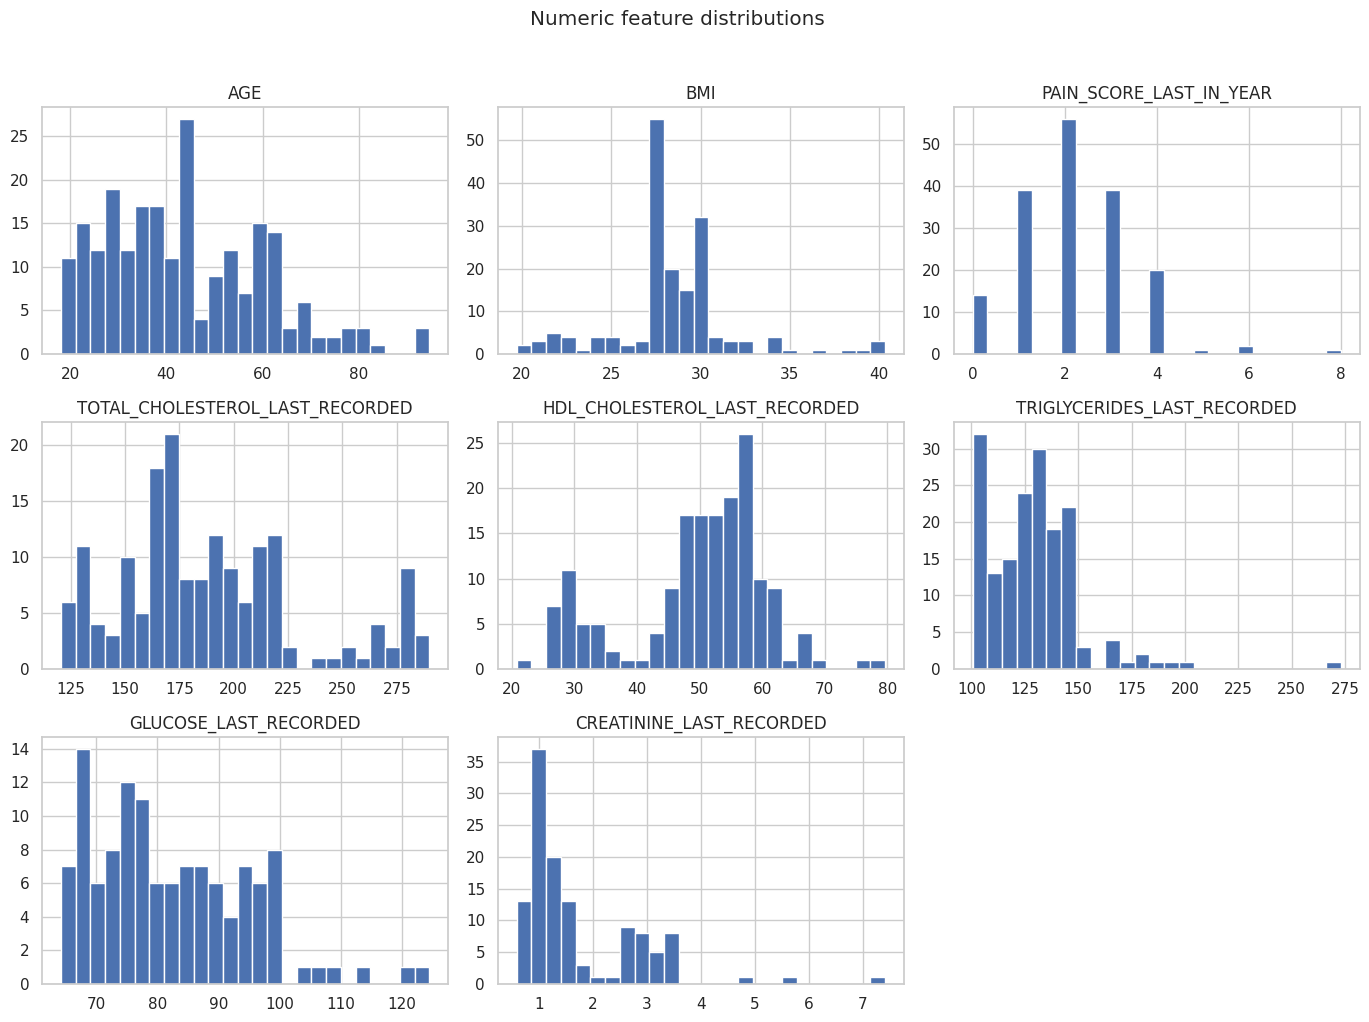

In [166]:
no_kids_data[measurement_cols].hist(figsize=(14, 10), bins=25)
plt.suptitle("Numeric feature distributions", y=1.02)
plt.tight_layout()
plt.show()

In [167]:
#displaying no_kids_data to see the unique values/ max and min
display(pd.DataFrame({
    "dtype": no_kids_data.dtypes.astype(str),
    "missing_n": no_kids_data.isna().sum(),
    "missing_percent": (100 * no_kids_data.isna().mean()).round(1),
    "unique_values": no_kids_data.nunique(dropna=True)
}).sort_values("missing_n", ascending=False))

print("Exact duplicate rows:", no_kids_data.duplicated().sum())
display(no_kids_data.describe(include="all").T)

,dtype,missing_n,missing_percent,unique_values
GLUCOSE_LAST_RECORDED,float64,104,46.2,107
GLUCOSE_DATE,datetime64[ns],104,46.2,101
CREATININE_LAST_RECORDED,float64,104,46.2,83
CREATININE_DATE,datetime64[ns],104,46.2,101
TOTAL_CHOLESTEROL_LAST_RECORDED,float64,56,24.9,99
TOTAL_CHOLESTEROL_DATE,datetime64[ns],56,24.9,97
TRIGLYCERIDES_DATE,datetime64[ns],56,24.9,97
TRIGLYCERIDES_LAST_RECORDED,float64,56,24.9,96
HDL_CHOLESTEROL_DATE,datetime64[ns],56,24.9,97
HDL_CHOLESTEROL_LAST_RECORDED,float64,56,24.9,99


Exact duplicate rows: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
PATIENT_ID,225,78,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BIRTH_DATE,225,NaN,NaN,NaN,1980-03-24 11:18:24,1930-06-11 00:00:00,1968-09-24 00:00:00,1981-07-29 00:00:00,1993-11-17 00:00:00,2006-10-30 00:00:00,NaN
SEX,225,2,M,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RACE,225,3,white,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
YEAR,225.0,NaN,NaN,NaN,2024.013333,2023.0,2023.0,2024.0,2025.0,2025.0,0.820932
PERIOD_START,225,NaN,NaN,NaN,2024-01-06 05:00:48,2023-01-01 00:00:00,2023-01-01 00:00:00,2024-01-01 00:00:00,2025-01-01 00:00:00,2025-01-01 00:00:00,NaN
PERIOD_END,225,NaN,NaN,NaN,2025-01-03 22:56:00,2023-08-22 00:00:00,2023-12-31 00:00:00,2024-12-31 00:00:00,2025-12-31 00:00:00,2025-12-31 00:00:00,NaN
RECORD_CUTOFF_DATE,225,NaN,NaN,NaN,2026-08-15 12:09:36,2023-08-22 00:00:00,2026-08-19 00:00:00,2026-08-22 00:00:00,2026-08-23 00:00:00,2026-08-25 00:00:00,NaN
ENCOUNTER_SYMPTOM_RECORDS,225.0,NaN,NaN,NaN,0.24,0.0,0.0,0.0,0.0,5.0,0.594018
ENCOUNTER_CHECK_UP_RECORDS,225.0,NaN,NaN,NaN,0.902222,0.0,0.0,0.0,1.0,15.0,2.028644


78 unique values after removing kids - so 78 adult patients in data set
Have removed !70 of the missing values for glucose and creatinine, but still leaves 104 missing values

Remove kids first!
then:
MISSING VALUES
Interogate
- glucose --> remove (because can't infer anything from not knowing if is fasted or not when no values are above what the post prandial value would need to be to be high
- creatinine - mean
- triclycerites - mean
- cholesterol- mean
- hdl - mean
- Height and weight
- pain - mean

should we
- remove entirely
- use a mean
- use a interpolation

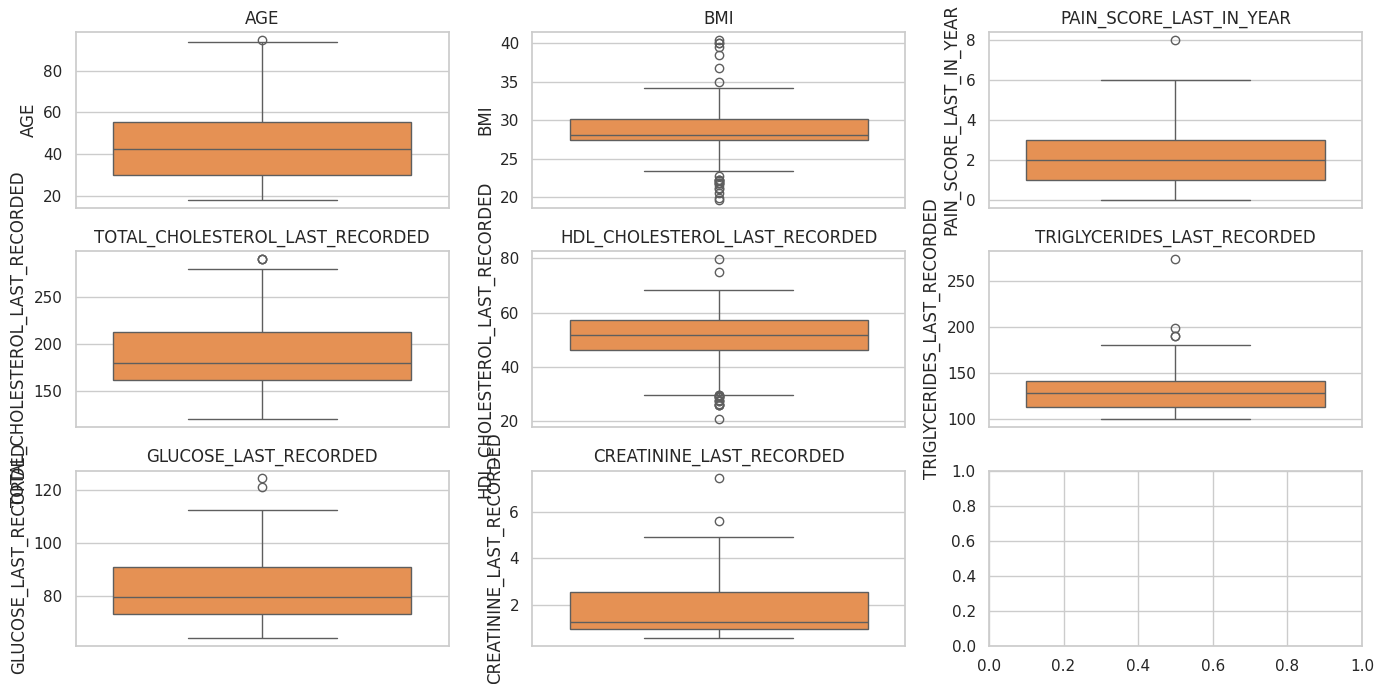

In [168]:
# Box plots for outlier inspection.
features_to_boxplot = no_kids_data[measurement_cols]

fig, axes = plt.subplots(3, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), features_to_boxplot):
    sns.boxplot(y=no_kids_data[col], ax=ax, color="#fd8d3c")
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [169]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr
    return lower, upper

col = "CREATININE_LAST_RECORDED"
lower, upper = iqr_bounds(no_kids_data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(no_kids_data.loc[(no_kids_data[col] < lower) | (no_kids_data[col] > upper), ["PATIENT_ID", col]].head(10))

col = "TRIGLYCERIDES_LAST_RECORDED"
lower, upper = iqr_bounds(no_kids_data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(no_kids_data.loc[(no_kids_data[col] < lower) | (no_kids_data[col] > upper), ["PATIENT_ID", col]].head(10))

col = "HDL_CHOLESTEROL_LAST_RECORDED"
lower, upper = iqr_bounds(no_kids_data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(no_kids_data.loc[(no_kids_data[col] < lower) | (no_kids_data[col] > upper), ["PATIENT_ID", col]].head(10))

col = "TOTAL_CHOLESTEROL_LAST_RECORDED"
lower, upper = iqr_bounds(no_kids_data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(no_kids_data.loc[(no_kids_data[col] < lower) | (no_kids_data[col] > upper), ["PATIENT_ID", col]].head(10))

col = "PAIN_SCORE_LAST_IN_YEAR"
lower, upper = iqr_bounds(no_kids_data[col].dropna())
print(f"{col}: lower={lower:.2f}, upper={upper:.2f}")
display(no_kids_data.loc[(no_kids_data[col] < lower) | (no_kids_data[col] > upper), ["PATIENT_ID", col]].head(10))

CREATININE_LAST_RECORDED: lower=-1.40, upper=4.94


,PATIENT_ID,CREATININE_LAST_RECORDED
107,5693c080-f485-91e7-54b9-ad9a8c12af62,5.58
114,57efda89-b582-bb08-8a2d-e06b2c184bfc,7.42


TRIGLYCERIDES_LAST_RECORDED: lower=70.03, upper=184.47


,PATIENT_ID,TRIGLYCERIDES_LAST_RECORDED
25,1d63466e-0cfd-eb12-77aa-d153393355e5,273.153097
61,355a4d50-2628-aa65-c336-deacf4d606fb,190.580000
62,355a4d50-2628-aa65-c336-deacf4d606fb,198.570000
286,f6745f8a-8107-443e-8946-3e6329d20408,190.079605


HDL_CHOLESTEROL_LAST_RECORDED: lower=29.55, upper=74.17


,PATIENT_ID,HDL_CHOLESTEROL_LAST_RECORDED
25,1d63466e-0cfd-eb12-77aa-d153393355e5,27.363376
52,31f368d9-3fdc-a15f-ccdc-fafa74a860e9,28.880000
53,31f368d9-3fdc-a15f-ccdc-fafa74a860e9,28.880000
54,31f368d9-3fdc-a15f-ccdc-fafa74a860e9,28.880000
76,3935e8a9-9b9f-fd00-fe22-bcb810d0330b,74.971635
143,7af6b271-f16d-21e1-882a-7bff71005a7b,27.770000
209,b50c66af-4d1c-7987-03d7-e5b65fdf880f,29.410000
216,bca1691f-8839-1d66-ed01-471134d55738,26.320000
217,bca1691f-8839-1d66-ed01-471134d55738,20.800000
218,bca1691f-8839-1d66-ed01-471134d55738,29.540000


TOTAL_CHOLESTEROL_LAST_RECORDED: lower=85.52, upper=289.88


,PATIENT_ID,TOTAL_CHOLESTEROL_LAST_RECORDED
219,bd4e49cb-391b-d08a-c7ab-b585e7bd5758,289.94
220,bd4e49cb-391b-d08a-c7ab-b585e7bd5758,289.94
221,bd4e49cb-391b-d08a-c7ab-b585e7bd5758,289.94


PAIN_SCORE_LAST_IN_YEAR: lower=-2.00, upper=6.00


,PATIENT_ID,PAIN_SCORE_LAST_IN_YEAR
52,31f368d9-3fdc-a15f-ccdc-fafa74a860e9,8.0


Looking at the outliers here, the triglyceride numbers all fall within plausible regions, with levels between 150-199 being borderline high and 200-499ml/dl being high and >500 being very high
--> so could take an average mean to outliers

HDL - all within normal range - so take mean

Total cholesterol is all within realistic ranges, with few outliers that are all from the same patient. take a mean average
The normal (desirable) range for total cholesterol is below 200 mg/dL, with 200–239 mg/dL considered borderline and ≥240 mg/dL high.

pain - only one outlier, do mean

creatinine, take a mean to fill in the gaps.



In [170]:
DEFAULT_FEATURES = [
    "SEX","RACE", "OBESITY_HISTORY", "PREDIABETES_HISTORY", "HYPERTENSION_HISTORY","ISCHEMIC_HEART_DISEASE_HISTORY",
    "CHRONIC_PAIN_HISTORY","ASTHMA_HISTORY","CHRONIC_KIDNEY_DISEASE_HISTORY",
    "SOCIAL_ISOLATION_HISTORY","UNEMPLOYMENT_HISTORY","HOUSING_UNSATISFACTORY_HISTORY",
    "AGE","BMI","PAIN_SCORE_LAST_IN_YEAR","TOTAL_CHOLESTEROL_LAST_RECORDED",
    "HDL_CHOLESTEROL_LAST_RECORDED","TRIGLYCERIDES_LAST_RECORDED","CREATININE_LAST_RECORDED",
    "ENCOUNTER_EMERGENCY_ROOM_RECORDS","ENCOUNTER_URGENT_CARE_RECORDS",
    "ENCOUNTER_INPATIENT_RECORDS", "ENCOUNTER_FOLLOW_UP_RECORDS","GLUCOSE_LAST_RECORDED"
]

# Variant space: remove or add columns and observe how clusters change.
FEATURES_TO_USE = DEFAULT_FEATURES.copy()

X = no_kids_data[FEATURES_TO_USE].copy()

# Extract numeric columns and explicitly EXCLUDE the history columns to avoid duplicate processing
numeric_cols_raw = X.select_dtypes(include=np.number).columns.tolist()
non_categ_cols = [col for col in numeric_cols_raw if col not in history_cols]

categ_cols1 = X.select_dtypes(exclude=np.number).columns.tolist()

# Ensure categorical missing values are np.nan, not pd.NA, before SimpleImputer.
for col in categ_cols1:
    X[col] = X[col].map(lambda value: np.nan if pd.isna(value) else str(value))

print("Non-categorical continuous features (excluding history):", non_categ_cols)
print("History features:", history_cols)
print("Categorical features:", categ_cols1)


Non-categorical continuous features (excluding history): ['AGE', 'BMI', 'PAIN_SCORE_LAST_IN_YEAR', 'TOTAL_CHOLESTEROL_LAST_RECORDED', 'HDL_CHOLESTEROL_LAST_RECORDED', 'TRIGLYCERIDES_LAST_RECORDED', 'CREATININE_LAST_RECORDED', 'ENCOUNTER_EMERGENCY_ROOM_RECORDS', 'ENCOUNTER_URGENT_CARE_RECORDS', 'ENCOUNTER_INPATIENT_RECORDS', 'ENCOUNTER_FOLLOW_UP_RECORDS', 'GLUCOSE_LAST_RECORDED']
History features: ['OBESITY_HISTORY', 'PREDIABETES_HISTORY', 'HYPERTENSION_HISTORY', 'ISCHEMIC_HEART_DISEASE_HISTORY', 'CHRONIC_PAIN_HISTORY', 'ASTHMA_HISTORY', 'CHRONIC_KIDNEY_DISEASE_HISTORY', 'SOCIAL_ISOLATION_HISTORY', 'UNEMPLOYMENT_HISTORY', 'HOUSING_UNSATISFACTORY_HISTORY']
Categorical features: ['SEX', 'RACE']


In [171]:
measurement_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categ_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

history_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", measurement_pipeline, non_categ_cols),
        ("hist", history_pipeline, history_cols),
        ("cat", categ_pipeline, categ_cols1)
    ]
)

X_prepared = preprocessor.fit_transform(X)
print("Prepared feature matrix shape:", X_prepared.shape)


Prepared feature matrix shape: (225, 27)


In [172]:
# 1. Dynamically retrieve the exact feature names directly from the fitted preprocessor pipeline
try:
    feature_names = preprocessor.get_feature_names_out()
    # Clean up prefixes like 'num__', 'hist__', 'cat__' for cleaner representation
    clean_feature_names = [
        name.split("__")[-1] for name in feature_names
    ]
except AttributeError:
    clean_feature_names = feature_names

# 2. Recreate X_cleaned_df with the exact matching feature names
X_cleaned_df = pd.DataFrame(
    X_prepared.toarray() if hasattr(X_prepared, 'toarray') else X_prepared,
    columns=clean_feature_names
)

# 3. Check missing values in original raw data vs. the cleaned, imputed DataFrame
print("Missing values in original DataFrame X:")
display(X.isna().sum())

print("\nMissing values in the cleaned DataFrame (X_cleaned_df):")
display(X_cleaned_df.isna().sum())

Missing values in original DataFrame X:


,0
SEX,0
RACE,0
OBESITY_HISTORY,0
PREDIABETES_HISTORY,0
HYPERTENSION_HISTORY,0
ISCHEMIC_HEART_DISEASE_HISTORY,0
CHRONIC_PAIN_HISTORY,0
ASTHMA_HISTORY,0
CHRONIC_KIDNEY_DISEASE_HISTORY,0
SOCIAL_ISOLATION_HISTORY,0



Missing values in the cleaned DataFrame (X_cleaned_df):


,0
AGE,0
BMI,0
PAIN_SCORE_LAST_IN_YEAR,0
TOTAL_CHOLESTEROL_LAST_RECORDED,0
HDL_CHOLESTEROL_LAST_RECORDED,0
TRIGLYCERIDES_LAST_RECORDED,0
CREATININE_LAST_RECORDED,0
ENCOUNTER_EMERGENCY_ROOM_RECORDS,0
ENCOUNTER_URGENT_CARE_RECORDS,0
ENCOUNTER_INPATIENT_RECORDS,0


In [173]:
# Verify that there are no remaining missing values in the processed dataset
print("Remaining missing values in the processed dataset:", X_cleaned_df.isna().sum().sum())
display(X_cleaned_df.head())

Remaining missing values in the processed dataset: 0


,AGE,BMI,PAIN_SCORE_LAST_IN_YEAR,TOTAL_CHOLESTEROL_LAST_RECORDED,HDL_CHOLESTEROL_LAST_RECORDED,TRIGLYCERIDES_LAST_RECORDED,CREATININE_LAST_RECORDED,ENCOUNTER_EMERGENCY_ROOM_RECORDS,ENCOUNTER_URGENT_CARE_RECORDS,ENCOUNTER_INPATIENT_RECORDS,...,ASTHMA_HISTORY,CHRONIC_KIDNEY_DISEASE_HISTORY,SOCIAL_ISOLATION_HISTORY,UNEMPLOYMENT_HISTORY,HOUSING_UNSATISFACTORY_HISTORY,SEX_F,SEX_M,RACE_asian,RACE_black,RACE_white
0,-0.113963,-0.194415,1.655967,-0.483969,0.867109,0.240419,-0.760467,-0.112664,-0.153763,-0.298940,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.053558,-0.194415,-0.999087,-0.429093,-0.449728,-0.751177,-0.772371,-0.112664,-0.153763,-0.298940,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.006846,-0.194415,-0.114069,-0.429093,-0.449728,-0.751177,-0.784274,-0.112664,-0.153763,-0.298940,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.435715,0.660622,-0.114069,-0.174543,0.294031,0.148824,-0.712852,-0.112664,-0.153763,-0.298940,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.496120,0.660622,-0.114069,-0.174543,0.294031,0.148824,-0.772371,0.340002,-0.153763,1.739285,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


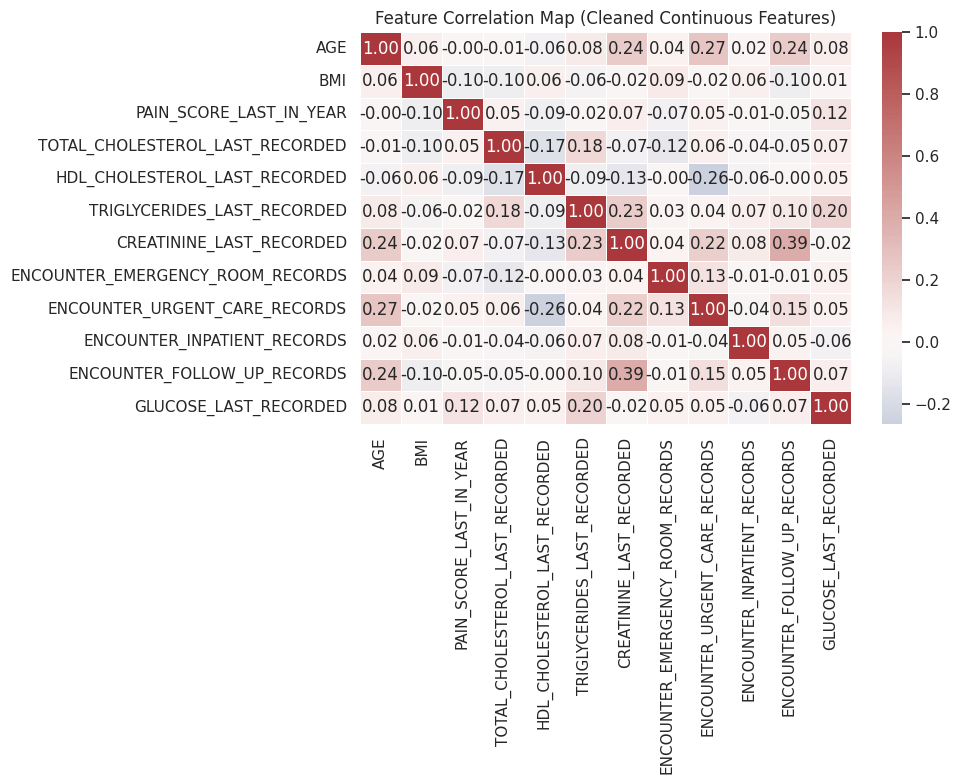

In [174]:
# Calculate correlations specifically for the cleaned, continuous measurement features
plt.figure(figsize=(10, 8))
corr = X_cleaned_df[non_categ_cols].corr()

# Plot the correlation heatmap for the core cleaned features
sns.heatmap(corr, cmap="vlag", center=0, linewidths=0.5, annot=True, fmt=".2f")
plt.title("Feature Correlation Map (Cleaned Continuous Features)")
plt.tight_layout()
plt.show()

For K=2, cluster sizes are 189, 36
For K=3, cluster sizes are 35, 189, 1
For K=4, cluster sizes are 87, 134, 3, 1
For K=5, cluster sizes are 98, 11, 90, 25, 1
For K=6, cluster sizes are 35, 100, 22, 3, 64, 1
For K=7, cluster sizes are 15, 29, 55, 1, 31, 91, 3
For K=8, cluster sizes are 78, 35, 3, 1, 6, 30, 9, 63


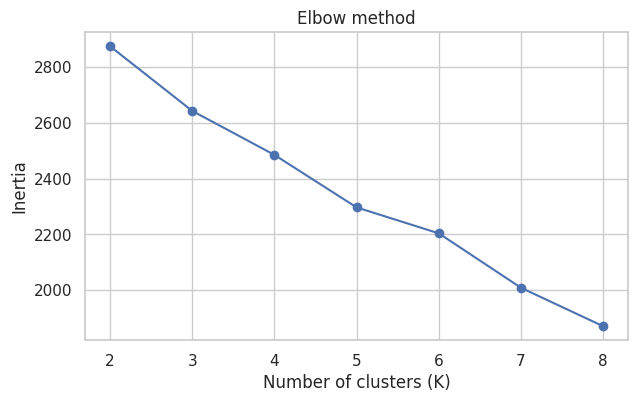

Text(0.5, 1.0, 'Silhouette score for different values of K')

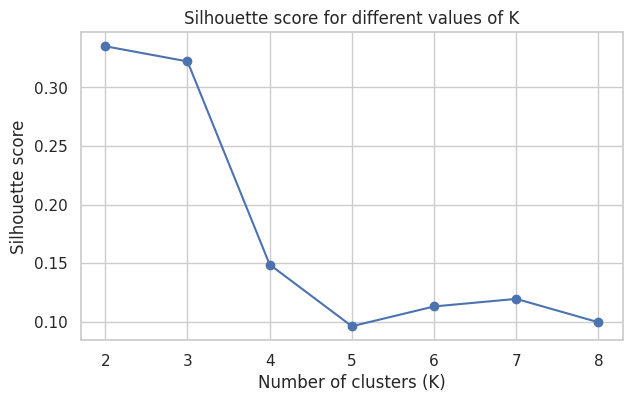

In [175]:
# Try different values of K and compare clustering diagnostics

k_values = range(2, 9)

inertias = []
silhouette_scores = []
cluster_sizes = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_prepared)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_prepared, labels)
    )

    # Count how many observations belong to each cluster
    sizes = pd.Series(labels).value_counts().sort_index().tolist()
    cluster_sizes.append(sizes)
    print(f"For K={k}, cluster sizes are {', '.join(map(str, sizes))}")


# Plot inertia
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()


# Plot silhouette score
plt.figure(figsize=(7, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score for different values of K")

In [176]:
# TODO: Choose a value for K after inspecting the plots.
CHOSEN_K = 2

kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20)
no_kids_data["kmeans_cluster"] = kmeans.fit_predict(X_prepared)
no_kids_data["kmeans_cluster"].value_counts().sort_index()

,count
kmeans_cluster,
0,189
1,36


In [177]:
# Cluster profiles: numeric summaries.
cluster_profile = no_kids_data.groupby("kmeans_cluster")[measurement_cols].mean().round(2)
display(cluster_profile)

# Categorical summaries.
for col in categ_cols:
    print("\n", col)
    display(pd.crosstab(no_kids_data["kmeans_cluster"], no_kids_data[col], normalize="index").round(2))

,AGE,BMI,PAIN_SCORE_LAST_IN_YEAR,TOTAL_CHOLESTEROL_LAST_RECORDED,HDL_CHOLESTEROL_LAST_RECORDED,TRIGLYCERIDES_LAST_RECORDED,GLUCOSE_LAST_RECORDED,CREATININE_LAST_RECORDED
kmeans_cluster,,,,,,,,
0,40.65,28.54,2.15,191.01,50.10,125.08,81.81,1.19
1,60.26,28.01,2.22,179.00,48.09,144.80,83.30,3.10



 SEX


SEX,F,M
kmeans_cluster,,
0,0.51,0.49
1,0.22,0.78



 RACE


RACE,asian,black,white
kmeans_cluster,,,
0,0.07,0.07,0.85
1,0.00,0.25,0.75


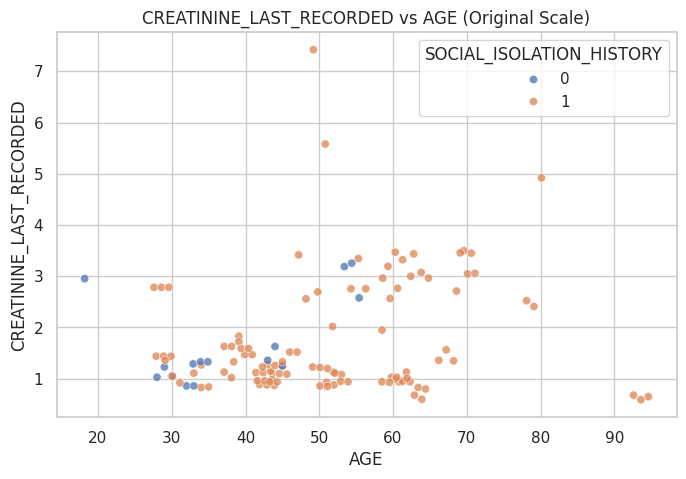

In [178]:

x_col = "AGE"
y_col = "CREATININE_LAST_RECORDED"
hue_col = "SOCIAL_ISOLATION_HISTORY"

# show original unscaled values on the plot axes
plt.figure(figsize=(8, 5))
sns.scatterplot(data=no_kids_data, x=x_col, y=y_col, hue=hue_col, alpha=0.75)
plt.title(f"{y_col} vs {x_col} (Original Scale)")
plt.show()


In [179]:
gmm = GaussianMixture(n_components=CHOSEN_K, random_state=RANDOM_STATE, covariance_type="full")
gmm_labels = gmm.fit_predict(X_prepared.toarray() if hasattr(X_prepared, "toarray") else X_prepared)
gmm_probs = gmm.predict_proba(X_prepared.toarray() if hasattr(X_prepared, "toarray") else X_prepared)

no_kids_data["gmm_cluster"] = gmm_labels
no_kids_data["gmm_max_probability"] = gmm_probs.max(axis=1)

display(no_kids_data[["PATIENT_ID", "kmeans_cluster", "gmm_cluster", "gmm_max_probability"]].head())
print("Low-confidence GMM assignments:")
display(no_kids_data.sort_values("gmm_max_probability").head(10)[["PATIENT_ID", "gmm_cluster", "gmm_max_probability", "AGE", "SOCIAL_ISOLATION_HISTORY", "PREDIABETES_HISTORY"]])

,PATIENT_ID,kmeans_cluster,gmm_cluster,gmm_max_probability
0,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,0,0,1.0
1,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,0,0,1.0
2,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,0,0,1.0
3,029c95e2-d252-d8d3-3626-7f347182d6d7,0,0,1.0
4,029c95e2-d252-d8d3-3626-7f347182d6d7,0,0,1.0


Low-confidence GMM assignments:


,PATIENT_ID,gmm_cluster,gmm_max_probability,AGE,SOCIAL_ISOLATION_HISTORY,PREDIABETES_HISTORY
143,7af6b271-f16d-21e1-882a-7bff71005a7b,0,0.999999,63.4,1,0
38,23da8e71-dfb9-9773-1bc1-7b5e31d085b5,0,1.000000,60.8,1,1
233,ca443842-f546-d34c-a69b-b044cfe007d9,0,1.000000,39.1,1,1
144,7af6b271-f16d-21e1-882a-7bff71005a7b,0,1.000000,64.4,1,0
4,029c95e2-d252-d8d3-3626-7f347182d6d7,0,1.000000,52.0,1,1
5,029c95e2-d252-d8d3-3626-7f347182d6d7,0,1.000000,53.0,1,1
2,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,0,1.000000,43.9,1,1
0,00bcbfc6-c7b9-bd0e-3d95-071f9fba6321,0,1.000000,41.9,1,1
8,06476266-59b1-ded7-4138-3c7543fd4981,0,1.000000,45.6,1,0
12,0b786670-17af-32e1-b2d2-f77c33874b30,1,1.000000,58.5,1,0


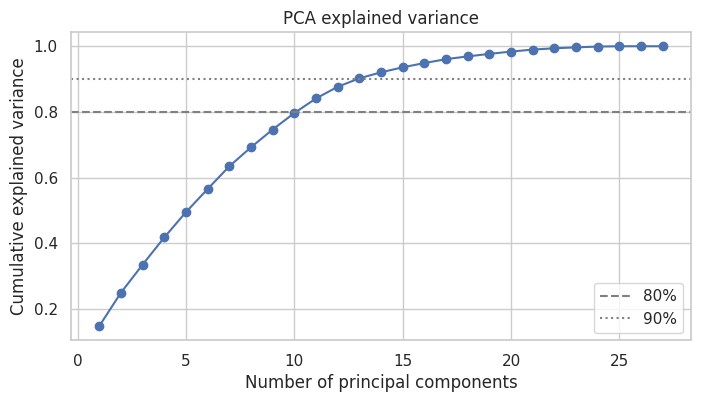

In [180]:
# PCA explained variance.
X_dense = X_prepared.toarray() if hasattr(X_prepared, "toarray") else X_prepared
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_dense)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_explained) + 1), cum_explained, marker="o")
plt.axhline(0.80, color="gray", linestyle="--", label="80%")
plt.axhline(0.90, color="gray", linestyle=":", label="90%")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.legend()
plt.show()

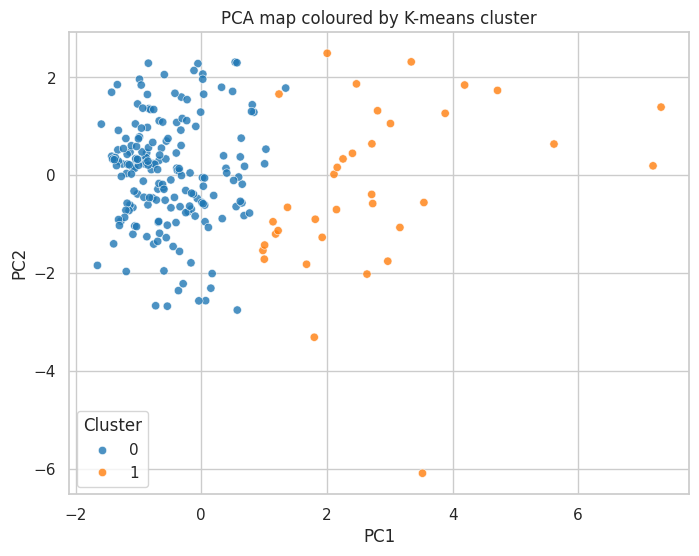

In [181]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca_2d.fit_transform(X_dense)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_pca[:, 0], y=Z_pca[:, 1], hue=no_kids_data["kmeans_cluster"], palette="tab10", alpha=0.8)
plt.title("PCA map coloured by K-means cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()

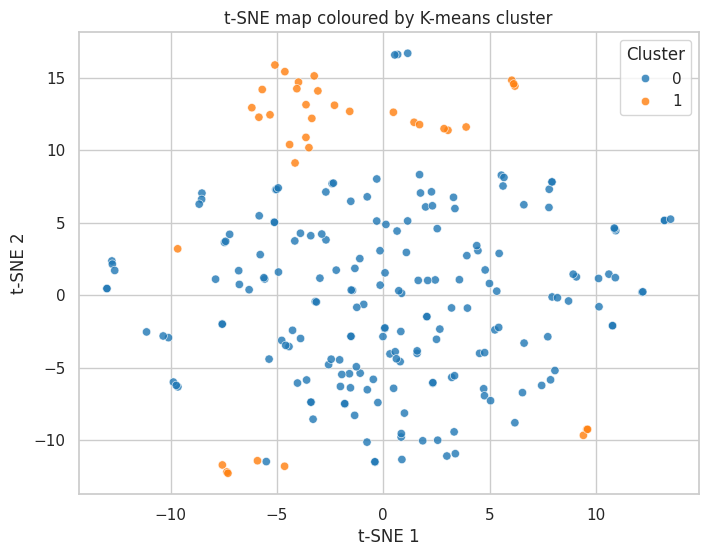

In [182]:
# t-SNE can take a little time.
tsne = TSNE(
    n_components=2,
    perplexity=40,
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)
Z_tsne = tsne.fit_transform(X_dense)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z_tsne[:, 0], y=Z_tsne[:, 1], hue=no_kids_data["kmeans_cluster"], palette="tab10", alpha=0.8)
plt.title("t-SNE map coloured by K-means cluster")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cluster")
plt.show()

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


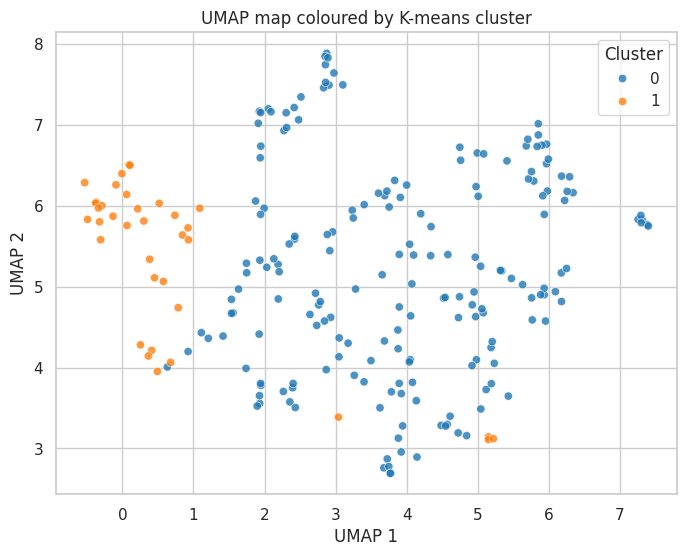

In [183]:
# Optional: UMAP if installed.
try:
    import umap
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.10, random_state=RANDOM_STATE)
    Z_umap = reducer.fit_transform(X_dense)

    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=Z_umap[:, 0], y=Z_umap[:, 1], hue=no_kids_data["kmeans_cluster"], palette="tab10", alpha=0.8)
    plt.title("UMAP map coloured by K-means cluster")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.legend(title="Cluster")
    plt.show()
except ImportError:
    print("UMAP is not installed.")